# Module 2 · My dataset
This notebook uses **your** `src/data.py` (built with Claude from `docs/data_spec.md`) and **your** `project.yaml`.
Run it top to bottom. The numbers and the grid go into Assignment 2.2. The observations at the end are **yours**.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import matplotlib.pyplot as plt
from src import data as dt
project = dt.load_project("project.yaml")
classes = project["classes"]
print(project)

{'name': 'plastic_bottles', 'classes': ['plastic-bottle'], 'format': 'yolo', 'source': {'folder': 'data/raw/plastic-bottle-2.0-v2'}}


## 1. Retrieve the data
Kaggle downloads once (later runs reuse the copy).

In [2]:
raw = dt.download(project)
print("raw dataset in:", raw)

raw dataset in: data\raw\plastic-bottle-2.0-v2


## 2. Convert it to one YOLO folder with a fixed split

In [3]:
root = dt.prepare(project, raw)
print("dataset ready in:", root)

Label lines: 18 polygon(s) converted to boxes; 0 dropped (0 malformed, 0 invalid). Details: data\plastic_bottles_yolo\label_conversions.csv
dataset ready in: data\plastic_bottles_yolo


## 3. Boxes per class — is it balanced?

train {'plastic-bottle': 2515}
val {'plastic-bottle': 1970}
test {'plastic-bottle': 1215}


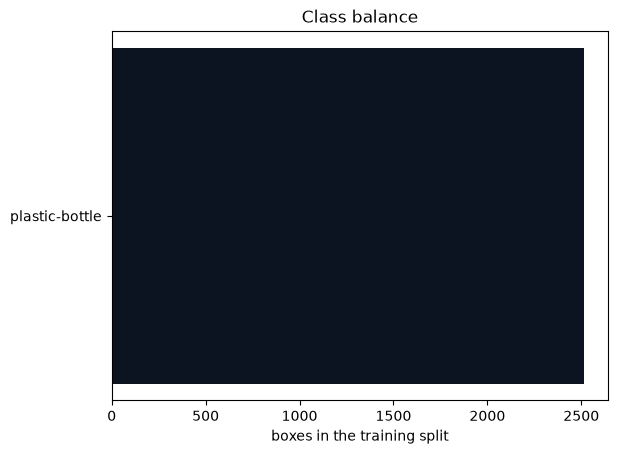

In [4]:
cc = dt.class_counts(root, classes)
for split, counts in cc.items(): print(split, counts)
plt.barh(classes, [cc["train"][c] for c in classes], color="#0C1422")
plt.xlabel("boxes in the training split"); plt.title("Class balance"); plt.show()

## 4. Images, boxes and box sizes per split

In [5]:
for split, s in dt.split_stats(root).items(): print(split, s)

train {'images': 1665, 'boxes': 2515, 'boxes_per_image': 1.51, 'median_box_area_pct': 11.28, 'small_boxes_lt_1pct': 126}
val {'images': 1394, 'boxes': 1970, 'boxes_per_image': 1.41, 'median_box_area_pct': 16.52, 'small_boxes_lt_1pct': 31}
test {'images': 700, 'boxes': 1215, 'boxes_per_image': 1.74, 'median_box_area_pct': 14.05, 'small_boxes_lt_1pct': 22}


## 5. Quality checks before trusting the data

In [6]:
rv = dt.review(root, len(classes))
for k, v in rv["counts"].items(): print(f"{k:28s} {v:5d}   {rv['examples'][k][:3]}")

images_without_label             0   []
labels_without_image             0   []
empty_labels                   417   ['train/000001_1672742699_webp.rf.8f7688ab63859102fd6df26ae813be0f.txt', 'train/011f4a7b7de1b6b6ebb007a5ea225040-png_240x240q80-png__webp.rf.d6b1e821269aa29bad29139487d58857.txt', 'train/0313dbfa9676f902e82ba8019248f456_jpg.rf.61a88ece227fc1cc5896341523f69ab1.txt']
out_of_range_boxes               0   []
unknown_class_ids                0   []
tiny_boxes_lt_0.1pct             4   ['train/pwb1310_jpg.rf.abf27041fa6149cae4c770e9649f4ff5.txt (box 14)', 'train/pwb2269_jpg.rf.49cc110957c4b308b5cb7ebc7960312b.txt (box 4)', 'train/pwb2269_jpg.rf.49cc110957c4b308b5cb7ebc7960312b.txt (box 12)']
duplicates_across_splits         2   ['test/PET1-748_jpg.rf.1711a7322b7b7d7653ac852697540723.jpg = val/plastic353_jpg.rf.9062494ec5af7b3c40be489c51c0b84c.jpg', 'test/PET1-761_jpg.rf.f3ff8a0b2ede99e423b753ab6ef4029e.jpg = val/plastic393_jpg.rf.bc0ca96b4f78c16a9ce9c2178c3f036c.jpg']


## 6. The 20-image inspection
Open the 20 images, compare every box with what you see.

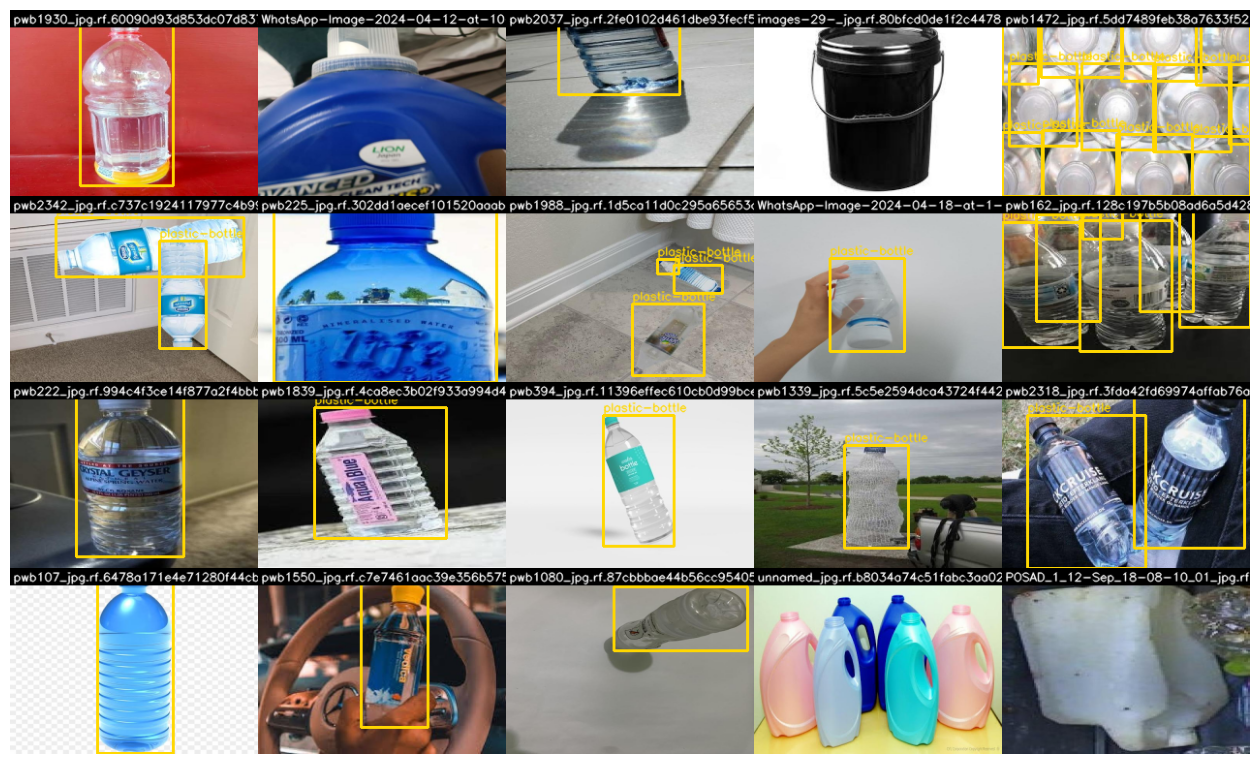

results\dataset_review.md


In [7]:
grid = dt.sample_grid(root, "train", n=20, seed=0, classes=classes)
plt.figure(figsize=(16, 10)); plt.imshow(grid); plt.axis("off"); plt.show()
print(dt.write_report(root, classes))      # results/dataset_review.md + results/dataset_sample_grid.jpg

## My observations (write them yourself — Assignment 2.2)
- **Boxes that do not match what I see** (image name, what is wrong): In the image showing several colored detergent bottles (`unnamed_jpg.rf.b8034a74c51fabc3aa02221d9657586a.jpg`, row 4, column 4 of the sample grid), I could not see any bounding boxes. If these containers belong to the plastic-bottle class, they may be missing annotations.
- **Class balance** (which class has the fewest boxes, and what that may cause): The dataset contains only one class, plastic-bottle, with 5,700 boxes. Therefore, there is no class imbalance to compare, but the model will only learn to detect this specific category.
- **The two things most likely to make this dataset hard:**
  1. Some images contain several bottles close together or overlapping, which could make it difficult for the model to locate each bottle accurately.
  2. The images have different backgrounds, lighting conditions, sizes, and viewpoints. Some bottles are also small or partially visible, which may make detection less reliable.